In [ ]:
"""
BCSE331P - Lab Assessment 5: Multivariate Analysis (Python)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
CSV_PATH = "orange_juice_withmissing.csv"

In [2]:
# 1. Load and examine
df = pd.read_csv(CSV_PATH)
num_all = df.select_dtypes(include=np.number).columns
df[num_all] = df[num_all].fillna(df[num_all].median())
df = df.drop_duplicates().reset_index(drop=True)
for c in ["StoreID", "STORE", "SpecialCH", "SpecialMM"]:
    df[c] = df[c].astype(int).astype(str)

numerical = ["WeekofPurchase", "PriceCH", "PriceMM", "DiscCH", "DiscMM", "LoyalCH",
             "SalePriceMM", "SalePriceCH", "PriceDiff", "PctDiscMM", "PctDiscCH", "ListPriceDiff"]
categorical = ["Purchase", "StoreID", "Store7", "SpecialCH", "SpecialMM", "STORE"]
print("Numerical variables  :", numerical)
print("Categorical variables:", categorical, "\n")
print(df.dtypes, "\n")

Numerical variables  : ['WeekofPurchase', 'PriceCH', 'PriceMM', 'DiscCH', 'DiscMM', 'LoyalCH', 'SalePriceMM', 'SalePriceCH', 'PriceDiff', 'PctDiscMM', 'PctDiscCH', 'ListPriceDiff']
Categorical variables: ['Purchase', 'StoreID', 'Store7', 'SpecialCH', 'SpecialMM', 'STORE'] 

Purchase              str
WeekofPurchase      int64
StoreID               str
PriceCH           float64
PriceMM           float64
DiscCH            float64
DiscMM            float64
SpecialCH             str
SpecialMM             str
LoyalCH           float64
SalePriceMM       float64
SalePriceCH       float64
PriceDiff         float64
Store7                str
PctDiscMM         float64
PctDiscCH         float64
ListPriceDiff     float64
STORE                 str
dtype: object 



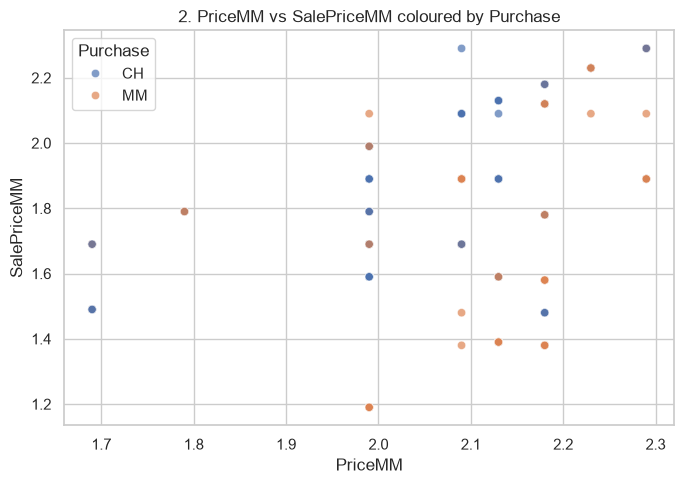

In [3]:
# 2. Scatter: 3 variables (x, y, colour)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PriceMM", y="SalePriceMM", hue="Purchase", alpha=0.7)
plt.title("2. PriceMM vs SalePriceMM coloured by Purchase")
plt.tight_layout(); plt.show()

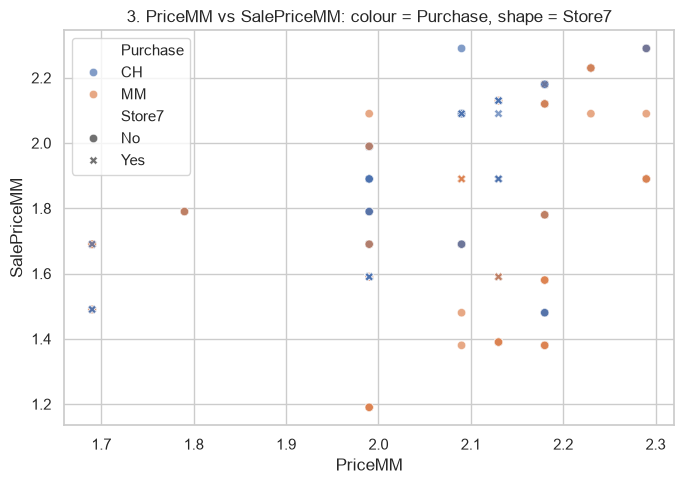

In [4]:
# 3. Scatter: 4 variables (x, y, colour, shape)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PriceMM", y="SalePriceMM", hue="Purchase", style="Store7", alpha=0.7)
plt.title("3. PriceMM vs SalePriceMM: colour = Purchase, shape = Store7")
plt.tight_layout(); plt.show()

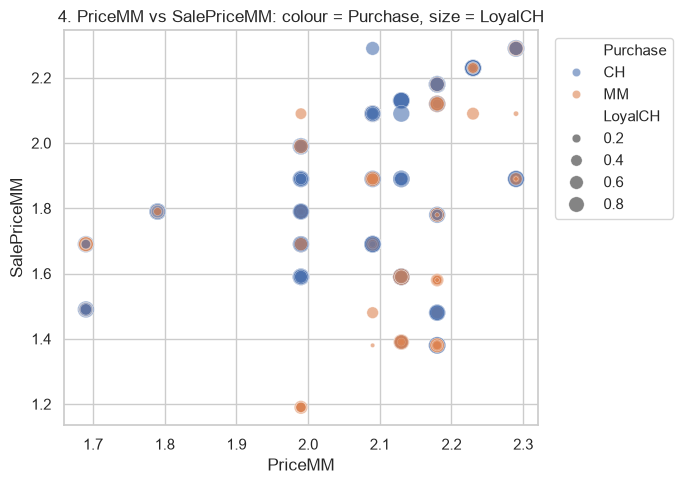

In [5]:
# 4. Scatter: 4 variables (x, y, colour, size)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PriceMM", y="SalePriceMM", hue="Purchase", size="LoyalCH",
                sizes=(10, 150), alpha=0.6)
plt.title("4. PriceMM vs SalePriceMM: colour = Purchase, size = LoyalCH")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

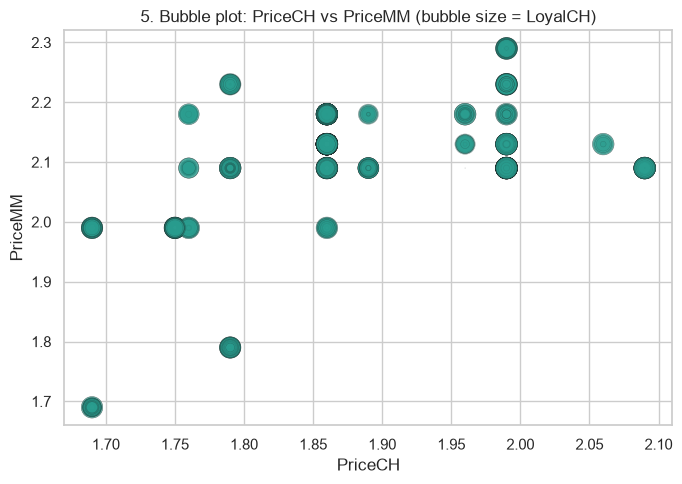

In [6]:
# 5. Bubble plot: three numeric variables
plt.figure(figsize=(7, 5))
plt.scatter(df["PriceCH"], df["PriceMM"], s=df["LoyalCH"] * 250, alpha=0.4,
            color="#2a9d8f", edgecolor="k", linewidth=0.3)
plt.xlabel("PriceCH"); plt.ylabel("PriceMM")
plt.title("5. Bubble plot: PriceCH vs PriceMM (bubble size = LoyalCH)")
plt.tight_layout(); plt.show()

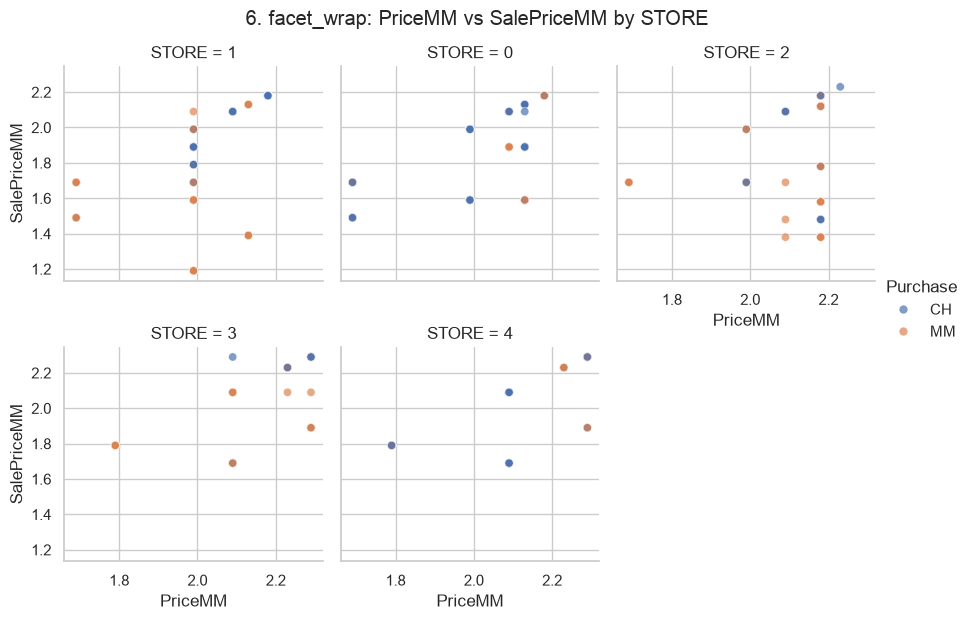

In [7]:
# 6. facet_wrap equivalent
g = sns.relplot(data=df, x="PriceMM", y="SalePriceMM", hue="Purchase", col="STORE",
                col_wrap=3, height=3, alpha=0.7, kind="scatter")
g.fig.suptitle("6. facet_wrap: PriceMM vs SalePriceMM by STORE", y=1.03)
plt.show()

In [ ]:
# 7. facet_grid equivalent: rows = Store7, columns = SpecialMM
g = sns.relplot(data=df, x="LoyalCH", y="SalePriceMM", hue="Purchase",
                row="Store7", col="SpecialMM", height=3, alpha=0.7)
g.fig.suptitle("7. facet_grid: LoyalCH vs SalePriceMM (rows = Store7, cols = SpecialMM)", y=1.03)
plt.show()
print("7. Compare panels: look at how the Purchase (CH / MM) colour mix and the "
      "LoyalCH-SalePriceMM slope change across Store7 and SpecialMM groups.\n")

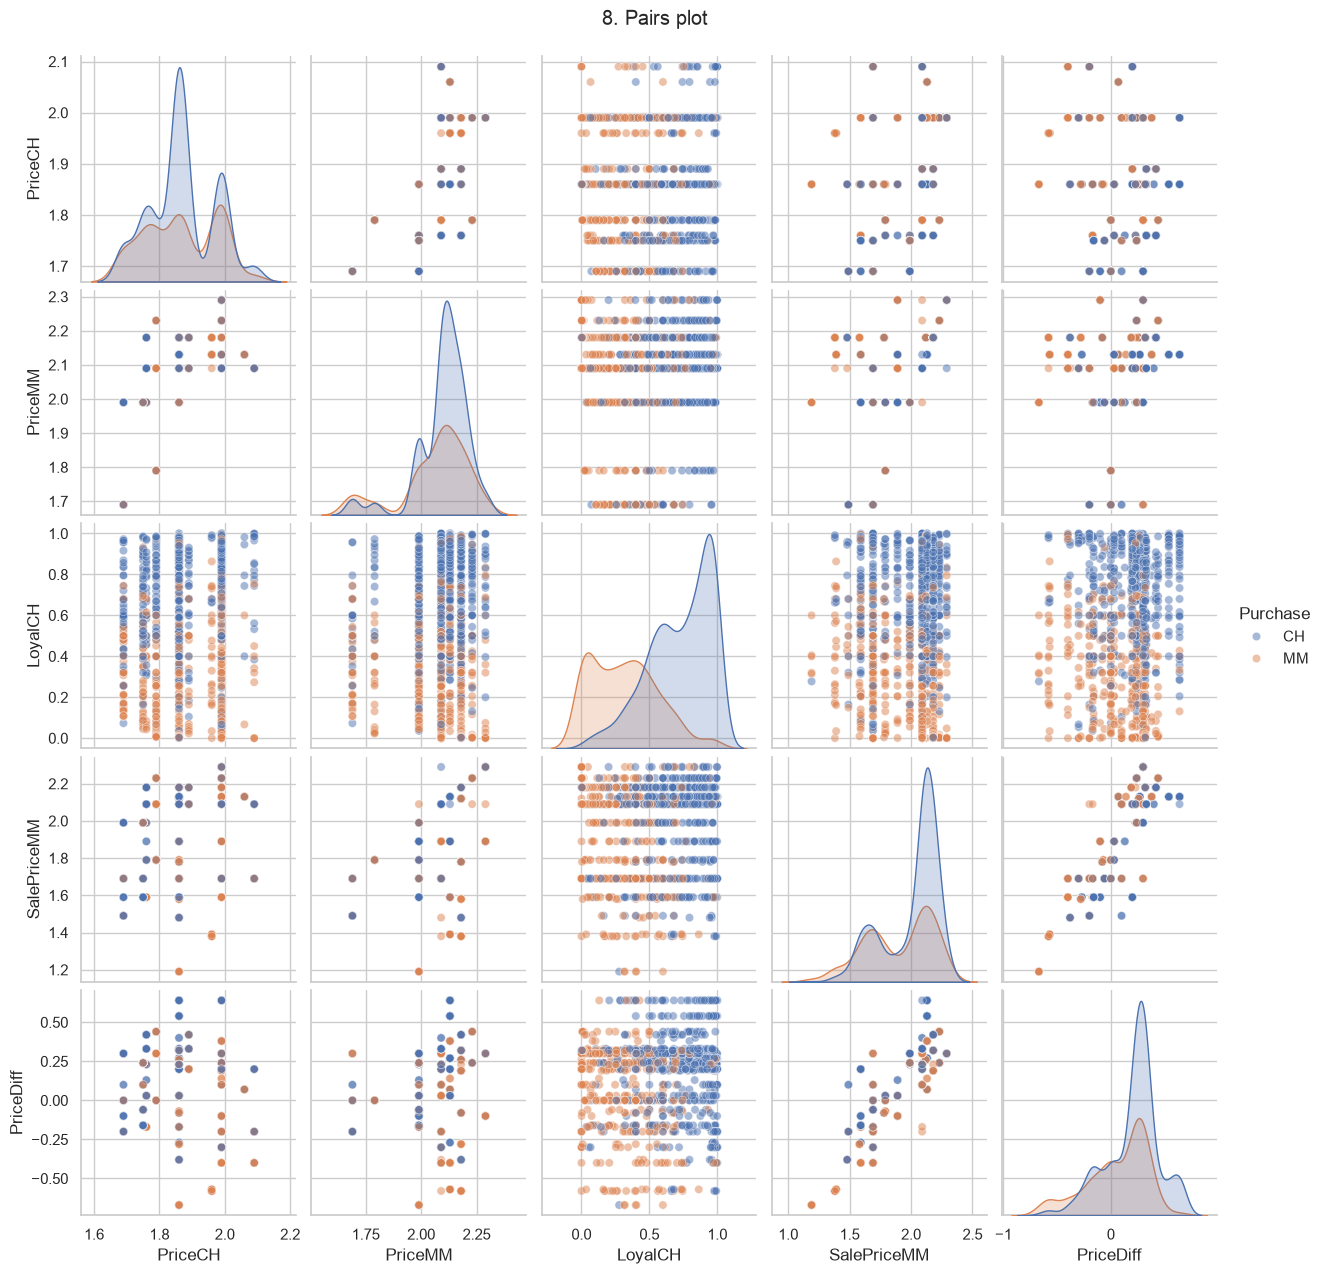

8. Correlations among selected variables:
              PriceCH  PriceMM  LoyalCH  SalePriceMM  PriceDiff
PriceCH         1.00     0.61     0.08         0.22      -0.11
PriceMM         0.61     1.00     0.12         0.53       0.29
LoyalCH         0.08     0.12     1.00         0.08       0.10
SalePriceMM     0.22     0.53     0.08         1.00       0.85
PriceDiff      -0.11     0.29     0.10         0.85       1.00 



In [8]:
# 8. Pairs plot (>= 4 numerical variables)
pair_vars = ["PriceCH", "PriceMM", "LoyalCH", "SalePriceMM", "PriceDiff"]
g = sns.pairplot(df[pair_vars + ["Purchase"]], hue="Purchase", corner=False, plot_kws={"alpha": 0.5})
g.fig.suptitle("8. Pairs plot", y=1.02)
plt.show()
print("8. Correlations among selected variables:\n", df[pair_vars].corr().round(2), "\n")

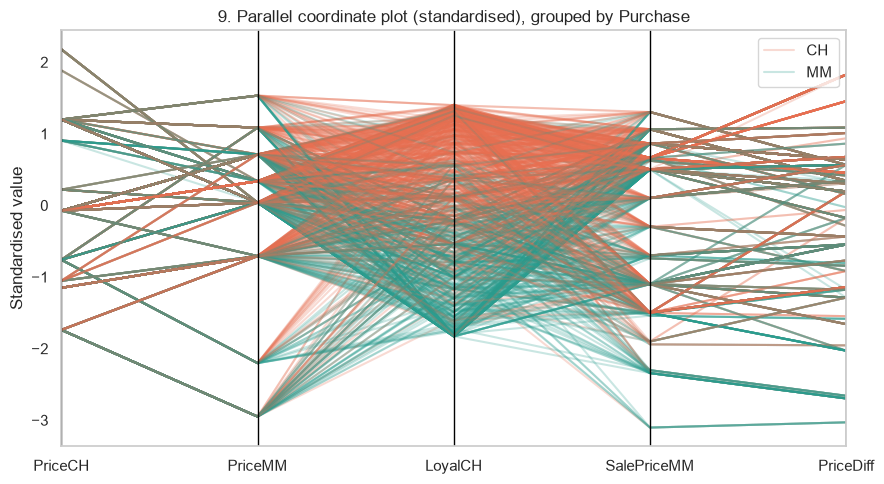

In [9]:
# 9. Parallel coordinate plot (standardised so axes are comparable)
from pandas.plotting import parallel_coordinates
pc = df[pair_vars].copy()
pc = (pc - pc.mean()) / pc.std()
pc["Purchase"] = df["Purchase"]
plt.figure(figsize=(9, 5))
parallel_coordinates(pc, "Purchase", color=["#e76f51", "#2a9d8f"], alpha=0.25)
plt.title("9. Parallel coordinate plot (standardised), grouped by Purchase")
plt.ylabel("Standardised value")
plt.tight_layout(); plt.show()